In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import root_numpy
import matplotlib

Welcome to JupyROOT 6.22/02


In [3]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [4]:
def getData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    return pd.DataFrame(data, columns=dfNames)

In [5]:
def flatten(data, column):
    a = []
    for row in range(0,len(data)):
        a.append(data[row][column])
    return np.concatenate(a)

In [6]:
def getFlattenedData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    a = []
    for branchName in branchNames:
        a.append(flatten(data, branchNames.index(branchName)))
    return pd.DataFrame(np.transpose(a), columns=dfNames)

In [7]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    return (n_ss-n_os)/(n_ss+n_os)

In [8]:
def getRcs(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    return (n_ss-n_os)/(n_ss+n_os)

In [9]:
def getRcErr(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    n_unweighted = dataframe[dataframe.b==1].shape[0] + dataframe[dataframe.b==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [10]:
def getRcsErr(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    n_unweighted = dataframe[dataframe.bs==1].shape[0] + dataframe[dataframe.bs==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [11]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [12]:
observables1 = ['pt','b','dr','z','epair','w','reject']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects']

In [13]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

In [14]:
df_geant = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=0 and bs!=-9 and 10<pts<30 and reject<=0 and rejects<=0')

In [15]:
df_geant.shape[0]

51831

In [16]:
rcs_0 = getRcs(applyCut(df_geant,'10<pts<15'))
rcs_err_0 = getRcsErr(applyCut(df_geant,'10<pts<15'))

In [17]:
rcs_1 = getRcs(applyCut(df_geant,'15<pts<20'))
rcs_err_1 = getRcsErr(applyCut(df_geant,'15<pts<20'))

In [18]:
rcs_2 = getRcs(applyCut(df_geant,'20<pts<30'))
rcs_err_2 = getRcsErr(applyCut(df_geant,'20<pts<30'))

In [19]:
print(rcs_0,rcs_1,rcs_2)
print(rcs_err_0,rcs_err_1,rcs_err_2)

-0.3692052788091335 -0.39125448790132333 -0.37896559276422115
0.006897886850187349 0.007238693512313462 0.006992252096104474


Note: results from running rc.C on geant_pid_new: -0.368983,-0.390918,-0.378657 (51888 jets)

In [20]:
df_pythia = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'b!=0 and b!=-9 and 10<pt<30 and reject<=0 and rejects<=0')

In [21]:
df_pythia.shape[0]

54245

In [22]:
rc_0 = getRc(applyCut(df_pythia,'10<pt<15'))
rc_err_0 = getRcErr(applyCut(df_pythia,'10<pt<15'))

In [23]:
rc_1 = getRc(applyCut(df_pythia,'15<pt<20'))
rc_err_1 = getRcErr(applyCut(df_pythia,'15<pt<20'))

In [24]:
rc_2 = getRc(applyCut(df_pythia,'20<pt<30'))
rc_err_2 = getRcErr(applyCut(df_pythia,'20<pt<30'))

In [25]:
print(rc_0,rc_1,rc_2)
print(rc_err_0,rc_err_1,rc_err_2)

-0.4128886987760696 -0.38305836146106215 -0.38081812496888595
0.0058527906739351595 0.007785236572479383 0.00732121902352467


Note: results from running rc.C on pythia_pid_new.root: -0.411037, -0.406995, -0.389326 (67746 jets)

Efficiency check

In [41]:
df_alltruth = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'b!=0 and b!=-9 and reject<=0 and rejects<=0 and 10<pt<30')

In [42]:
sum(df_alltruth[df_alltruth.b==-1]['w'])

0.00020328092193935138

In [43]:
sum(df_alltruth[df_alltruth.b==1]['w'])

8.601298728249523e-05

In [51]:
df_truptcut = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=-9 and b!=0 and b!=-9 and reject<=0 and rejects<=0 and 10<pt<30')

In [52]:
sum(df_truptcut[df_truptcut.b==-1]['w'])

2.7760520745344353e-05

In [46]:
sum(df_truptcut[df_truptcut.b==1]['w'])

1.227057979537316e-05

Matching requirements: jets are matched, reco leading particles are both charged, but no requirement for truth being charged

In [26]:
df = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=0 and bs!=-9 and b!=-9 and reject<=0 and rejects<=0 and 10<pts<30')

In [27]:
df.shape[0]

50087

In [28]:
rcs_0 = getRcs(applyCut(df,'10<pts<15'))
rcs_err_0 = getRcsErr(applyCut(df,'10<pts<15'))

In [29]:
rcs_1 = getRcs(applyCut(df,'15<pts<20'))
rcs_err_1 = getRcsErr(applyCut(df,'15<pts<20'))

In [30]:
rcs_2 = getRcs(applyCut(df,'20<pts<30'))
rcs_err_2 = getRcsErr(applyCut(df,'20<pts<30'))

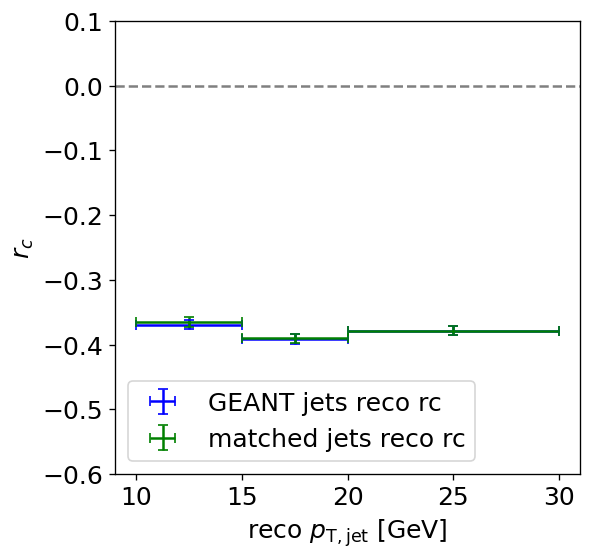

In [31]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [-0.3692052788091335,-0.39125448790132333,-0.37896559276422115], xerr=[2.5, 2.5, 5], yerr=[0.006897886850187349,0.007238693512313462,0.006992252096104474], capsize=3, color='b', ls='none', label='GEANT jets reco rc')
plt.errorbar([12.5, 17.5, 25], [rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='matched jets reco rc')
plt.xlabel('reco $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend()

Matching requirements: jets are matched, truth leading particles are both charged, but no requirement for reco. pT cut on truth

In [32]:
df = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'b!=0 and bs!=-9 and b!=-9 and reject<=0 and rejects<=0 and 10<pt<30')

In [33]:
df.shape[0] # why is this number so low? b!=0 removed many jets with pi0 as leading and subleading. see below

27815

In [34]:
rc_0 = getRc(applyCut(df,'10<pt<15'))
rc_err_0 = getRcErr(applyCut(df,'10<pt<15'))

In [35]:
rc_1 = getRc(applyCut(df,'15<pt<20'))
rc_err_1 = getRcErr(applyCut(df,'15<pt<20'))

In [36]:
rc_2 = getRc(applyCut(df,'20<pt<30'))
rc_err_2 = getRcErr(applyCut(df,'20<pt<30'))

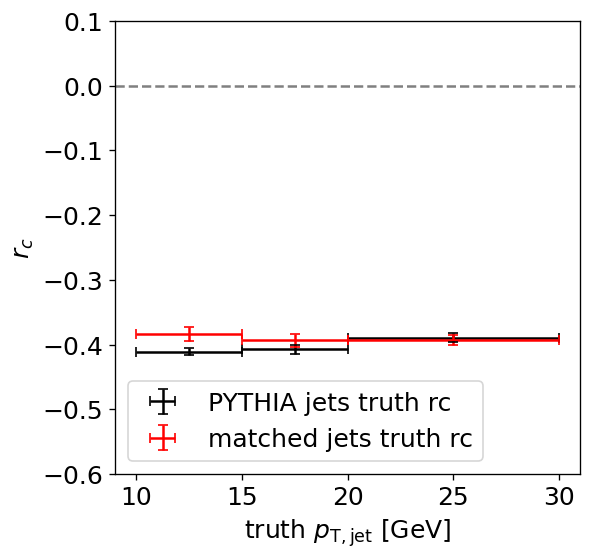

In [37]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [-0.411037,-0.406995,-0.389326], xerr=[2.5, 2.5, 5], yerr=[0.00528726, 0.0068786, 0.0065369], capsize=3, color='k', ls='none', label='PYTHIA jets truth rc')
plt.errorbar([12.5, 17.5, 25], [rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 5], yerr=[rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='matched jets truth rc')
plt.xlabel('truth $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend()

Check the effects of pi0 in pythia truth

In [38]:
observables1 = ['pt','b','dr','z','epair','w','reject','pid1','pid2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pid1s','pid2s']

In [39]:
df = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),\
              'b!=-9 and reject<=0 and rejects<=0 and pt>10')

In [40]:
df.shape[0]

186484

In [41]:
sum(df['w'])

0.0007644656588911003

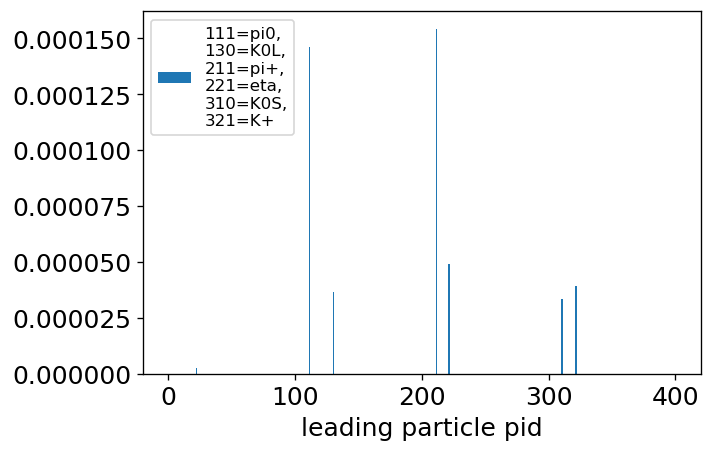

In [42]:
plt.hist(df['pid1'], range=(0,400), bins=400, weights=df['w'], label='111=pi0,\n130=K0L,\n211=pi+,\n221=eta,\n310=K0S,\n321=K+')
plt.xlabel('leading particle pid')
plt.legend(fontsize=10, loc='upper left')
plt.show()

In [43]:
df = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),\
              '(pid1==111 or pid2==111) and b!=-9 and reject<=0 and rejects<=0 and pt>10')

In [44]:
df.shape[0]

68599

In [45]:
sum(df['w'])

0.0002752414286856311